In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns 

from scipy.stats import norm

# Problem 7

In [2]:
# Part a
df = pd.read_csv('./data/ames_prices.csv')
df['central_air'] = (df['Central.Air'] == 'Y').astype(int)

p_hat = np.mean(df['central_air'])
print(p_hat)

0.9331058020477816


In [3]:
# Part b
np.random.seed(42)
R = 10_000
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(df), len(df))
    p_hat_t = np.mean(df['central_air'].iloc[idx])
    results.append(p_hat_t)
results = np.array(results)

print(results)

[0.92866894 0.92969283 0.9331058  ... 0.92901024 0.9337884  0.93788396]


#### Part B
Seed = 42 
Replications = 10,000

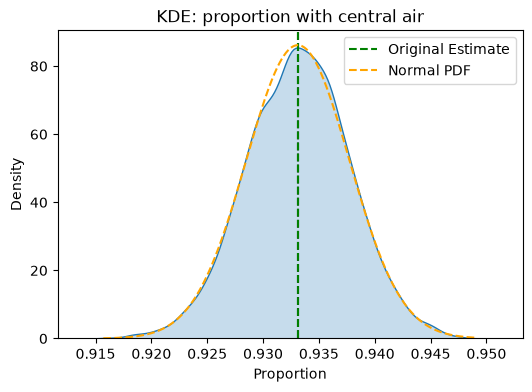

In [4]:
# Part c

sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
standard_error
fig, ax = plt.subplots(figsize=(6, 4))

sns.kdeplot(sample, fill=True, ax=ax)
ax.axvline(mean, color='black', linestyle='--')
ax.set_title('KDE: proportion with central air')
ax.set_xlabel('Proportion')
ax.set_ylabel('Density')
ax.axvline(p_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax.plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)
ax.legend()
plt.show()


In [5]:
print(standard_error)


0.0046301541057246825


In [6]:
# Part d
L = p_hat - 1.645 * standard_error
U = p_hat + 1.645 * standard_error
print(f'90% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = p_hat - 1.960 * standard_error
U = p_hat + 1.960 * standard_error
print(f'95% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = p_hat - 2.576 * standard_error
U = p_hat + 2.576 * standard_error
print(f'99% Confidence Interval: [{L:.4f}, {U:.4f}]')

z = (p_hat - 0.90) / standard_error
print(z)

90% Confidence Interval: [0.9255, 0.9407]
95% Confidence Interval: [0.9240, 0.9422]
99% Confidence Interval: [0.9212, 0.9450]
7.15004323654149


##### Part e
So, p-hat is equal to about 0.9331, where the standard error is also 0.0046. At 90%, 95%, and 99% intervals, the ranges are 0.9255 to 0.9407, 0.9240 to 0.9422, and 0.9212 to 0.9450, respectively. Looking at all three, the null value of 0.90 is outside all three, so we reject H0 such that p = 0.90 at significance levels 0.10, 0.05, and 0.01. Z is equal to about 7.15, and so the share of Ames homes with central air is about 3 percentage points above 90%. 

# Problem 8

In [7]:
# Part a
x = np.arcsinh(df['area'])
y = np.arcsinh(df['price'])

r_hat = np.corrcoef(x,y)[0,1]
print(r_hat)

0.7231661530091358


In [8]:
# Part b
np.random.seed(42)
R = 10_000
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(df), len(df))
    r_hat_t = np.corrcoef(x.iloc[idx], y.iloc[idx])[0,1]
    results.append(r_hat_t)
results = np.array(results)

print(results)

[0.70428183 0.73060066 0.7179182  ... 0.7234758  0.72599281 0.73197654]


#### Part b
Seed = 42
Replications = 10000

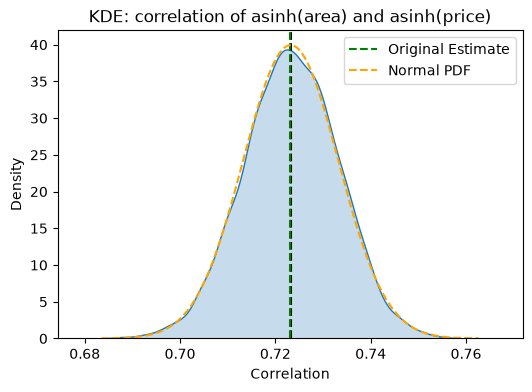

In [9]:
# Part c

sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
standard_error
fig, ax = plt.subplots(figsize=(6, 4))

sns.kdeplot(sample, fill=True, ax=ax)
ax.axvline(mean, color='black', linestyle='--')
ax.set_title('KDE: correlation of asinh(area) and asinh(price)')
ax.set_xlabel('Correlation')
ax.set_ylabel('Density')
ax.axvline(r_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax.plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)
ax.legend()
plt.show()

In [10]:
print(standard_error)


0.00999055987302171


In [11]:
# Part d
L = r_hat - 1.645 * standard_error
U = r_hat + 1.645 * standard_error
print(f'90% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = r_hat - 1.960 * standard_error
U = r_hat + 1.960 * standard_error
print(f'95% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = r_hat - 2.576 * standard_error
U = r_hat + 2.576 * standard_error
print(f'99% Confidence Interval: [{L:.4f}, {U:.4f}]')

z = (r_hat - 0) / standard_error
print(z)

90% Confidence Interval: [0.7067, 0.7396]
95% Confidence Interval: [0.7036, 0.7427]
99% Confidence Interval: [0.6974, 0.7489]
72.38494761058966


The R-hat is equal to 0.7232, and the standard error is equal to 0.0100. The intervals for 90%, 95%, and 99% are 0.7067 to 0.7396, 0.7036 to 0.7427, and 0.6974 to 0.7489, respectively. The null value is 0 is outside all three intervals, so we reject H0 such that p = 0, and the significance levels are equal to 0.10, 0.05, and 0.01, for which z = 72.4. What this means is larger homes tend to sell for more, and there's a strong association for that. 

#### Part e

The reason why area and price are paired is because correlations describe how variables move together within, in this case, the same house. Using one index for both actually keeps each house's area within its own sort of price, which would mimic drawing a new sample of houses. So if we resampled area and price separately, where one house's area would be paired with another house's price, that destroys the relationship. The bootstrapped correlations would be near zero and would not measure the sampling variability of R-hat. 

# Problem 9

In [12]:
# Part a
met = pd.read_csv('./data/metabric.csv')
rdf = met.loc[:, ['Overall Survival (Months)']].dropna()

print(len(met), len(rdf))
print(met['Overall Survival Status'].value_counts())

mu_hat = np.mean(rdf['Overall Survival (Months)'])
print(mu_hat)
print(mu_hat/12)

1343 1343
Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64
129.09429138744105
10.757857615620088


In [13]:
# Part b
np.random.seed(42)
R = 10_000
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(rdf), len(rdf))
    mu_hat_t = np.mean(rdf['Overall Survival (Months)'].iloc[idx])
    results.append(mu_hat_t)
results = np.array(results)

print(results)

[129.3839166  129.79066766 123.53256391 ... 128.00282949 130.02849342
 127.31660462]


### Part b
Seed = 42
Replications = 10000

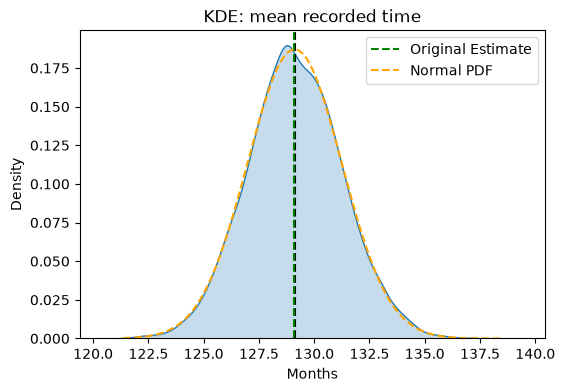

In [14]:
# Part c

sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
standard_error
fig, ax = plt.subplots(figsize=(6, 4))

sns.kdeplot(sample, fill=True, ax=ax)
ax.axvline(mean, color='black', linestyle='--')
ax.set_title('KDE: mean recorded time')
ax.set_xlabel('Months')
ax.set_ylabel('Density')
ax.axvline(mu_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax.plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)
ax.legend()
plt.show()

In [15]:
print(standard_error)


2.1334113281608316


In [16]:
# Part d
L = mu_hat - 1.645 * standard_error
U = mu_hat + 1.645 * standard_error
print(f'90% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = mu_hat - 1.960 * standard_error
U = mu_hat + 1.960 * standard_error
print(f'95% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = mu_hat - 2.576 * standard_error
U = mu_hat + 2.576 * standard_error
print(f'99% Confidence Interval: [{L:.4f}, {U:.4f}]')

z = (mu_hat - 120) / standard_error
print(z)

90% Confidence Interval: [125.5848, 132.6038]
95% Confidence Interval: [124.9128, 133.2758]
99% Confidence Interval: [123.5986, 134.5900]
4.2627932398207715


So, μ = 129.094 months, or 10.758 years. The standard error is then 2.133 months, or roughly about 0.178 years. The intervals in months for 90%, 95%, and 99% are 125.585 to 132.604, 124.913 to 133.276, and 123.599 to 134.590, respectively. In years, it would be from 10.465 to 11.050, and 10.409 to 11.106, and 10.300 to 11.216. The null value is 120 months, or about just 10 years, which is below all three intervals. We reject the H0 such that μ = 120 at significance levels 0.10, 0.05, and 0.01, where Z = 4.26. 

### Part e

The reason why this is not a mean lifetime is because each value is time to death or the time of the last follow-up. The value counts actually show about 575 out of the total 1,343 patients that are still living (Right-Censored), and for them, the recorded time is only a lower bound of their actual survival time. The sample mean actually mixes actual death times with follow-up times, So it understates the true unrestricted mean lifetime. Since it estimates the mean recorded time, it depends on how long patients were actually followed. 

# Problem 10

In [17]:
# Part a
nh = pd.read_csv('./data/nhanes_data_17_18.csv', low_memory=False)
rdf = nh.loc[nh['AgeInYearsAtScreening'] >= 18, ['SleepHoursWeekdaysOrWorkdays']].dropna()

print(f'Adults with observed weekday sleep: {len(rdf)}')

sleep_hat = np.mean(rdf['SleepHoursWeekdaysOrWorkdays'])
print(sleep_hat)

Adults with observed weekday sleep: 5489
7.62124248496994


In [18]:
# Part b
np.random.seed(42)
R = 10_000
results = []
for t in range(R):
    idx = np.random.randint( 0 , len(rdf), len(rdf))
    sleep_hat_t = np.mean(rdf['SleepHoursWeekdaysOrWorkdays'].iloc[idx])
    results.append(sleep_hat_t)
results = np.array(results)

print(results)

[7.62470395 7.59910731 7.65212243 ... 7.64547276 7.63381308 7.65102933]


### Part b
Seed = 42
Replications = 10000

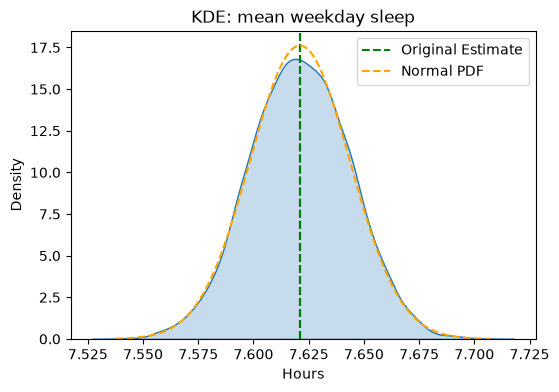

In [19]:
# Part c

sample = results
mean = np.mean(sample)
standard_error = np.std(sample, ddof=1)
standard_error
fig, ax = plt.subplots(figsize=(6, 4))

sns.kdeplot(sample, fill=True, ax=ax)
ax.axvline(mean, color='black', linestyle='--')
ax.set_title('KDE: mean weekday sleep')
ax.set_xlabel('Hours')
ax.set_ylabel('Density')
ax.axvline(sleep_hat, color='green', linestyle='--',
    label='Original Estimate')
x_grid = np.linspace(sample.min(), sample.max(), 500)
ax.plot(
    x_grid,
    norm.pdf(x_grid, loc=mean, scale=standard_error),
    color='orange',
    linestyle='--',
    label='Normal PDF'
)
ax.legend()
plt.show()

In [20]:
print(standard_error)

0.022652095010279354


In [21]:
# Part d
L = sleep_hat - 1.645 * standard_error
U = sleep_hat + 1.645 * standard_error
print(f'90% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = sleep_hat - 1.960 * standard_error
U = sleep_hat + 1.960 * standard_error
print(f'95% Confidence Interval: [{L:.4f}, {U:.4f}]')
L = sleep_hat - 2.576 * standard_error
U = sleep_hat + 2.576 * standard_error
print(f'99% Confidence Interval: [{L:.4f}, {U:.4f}]')

z = (sleep_hat - 8) / standard_error
print(z)

90% Confidence Interval: [7.5840, 7.6585]
95% Confidence Interval: [7.5768, 7.6656]
99% Confidence Interval: [7.5629, 7.6796]
-16.720639519575666


The sleep hat is equal to about 7.6212 hours, and the standard error is equal to 0.0227. The intervals for 90%, 95%, and 99% are 7.5840 to 7.6585, 7.5768 to 7.6656, and 7.5629 to 7.6796, respectively. The null value is actually above all three intervals when we're looking at 8, so we actually reject H0 such that the sleep is actually equal to 8 at significant levels 0.1, 0.05, and 0.01, where z is equal to -16.72. 

#### Part e

In this case, the result is actually a statistically significant one because the confidence intervals all sit well below 8 hours, so we actually reject the null. That is mostly just because we have a large sample, which makes the standard error very, very small. The average is only about 0.38 hours, or roughly about 23 minutes below 8 hours, which is a small difference in real life. Statistical significance and practical significance don't tell the same story in this case. In this data, we also ignore the survey design and treat everyone equally, so these results aren't actually representative of everyone. It's not nationally representative, and the intervals aren't survey-adjusted either. 